# Winners-loosers 

In [102]:
import pandas as pd
import numpy as np
import scipy as sp

from os import listdir
from collections import OrderedDict

import seaborn as sns
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
import matplotlib as mpl

In [103]:
import sys
sys.path.append("../functions/")
import abundance_sim_analysis

In [104]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


**Load and process data**

In [105]:
abundances = {}
for file in listdir("../output/Venturelli2018/results_steadiercom/results_growth_test/"):
    if file.endswith("_abundance.tsv"):

        abundances[file.replace("_abundance.tsv","")] = pd.read_csv(f"../output/Venturelli2018/results_steadiercom/results_growth_test/{file}",sep="\t")

abundances_df = pd.concat(abundances)
abundances_df.reset_index(drop=True)
abundances_df.member = abundances_df.member.map(lambda x: x.split("_")[0][0].upper()+x.split("_")[1][0].upper())

**Filter out 1-member communities**

In [106]:
count_members_sample = abundances_df[["sample","community"]].value_counts()
count_above_1 = count_members_sample[count_members_sample>1].index
abundance_filtered = abundances_df[abundances_df[["sample", "community"]].apply(tuple, axis=1).isin(count_above_1)
].copy()

In [107]:
len(set(abundance_filtered[["sample","community"]].value_counts().index))

3876

In [108]:
len(set(abundances_df[["sample","community"]].value_counts().index))

19500

**Do a count of how often members are predicted to grow together**

In [109]:
abundance_filtered.value_counts("member")

member
FP    1312
CA    1256
ER    1044
CH     912
EL     904
BH     889
DP     389
BT     342
BU     336
BO     331
BV     281
PC     213
Name: count, dtype: int64

In [110]:
len(abundances_df["sample"].unique())

1500

In [111]:
len(abundance_filtered["sample"].unique())

1407

### Co-growth count - in how many samples are two members predicted to grow together?  (NB: member1=member2 is set to 0)

[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.
[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.
[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.
[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.
[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.
[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.
[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.
[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.
[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.
[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.
[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.
[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.
[INFO] Make_co_g

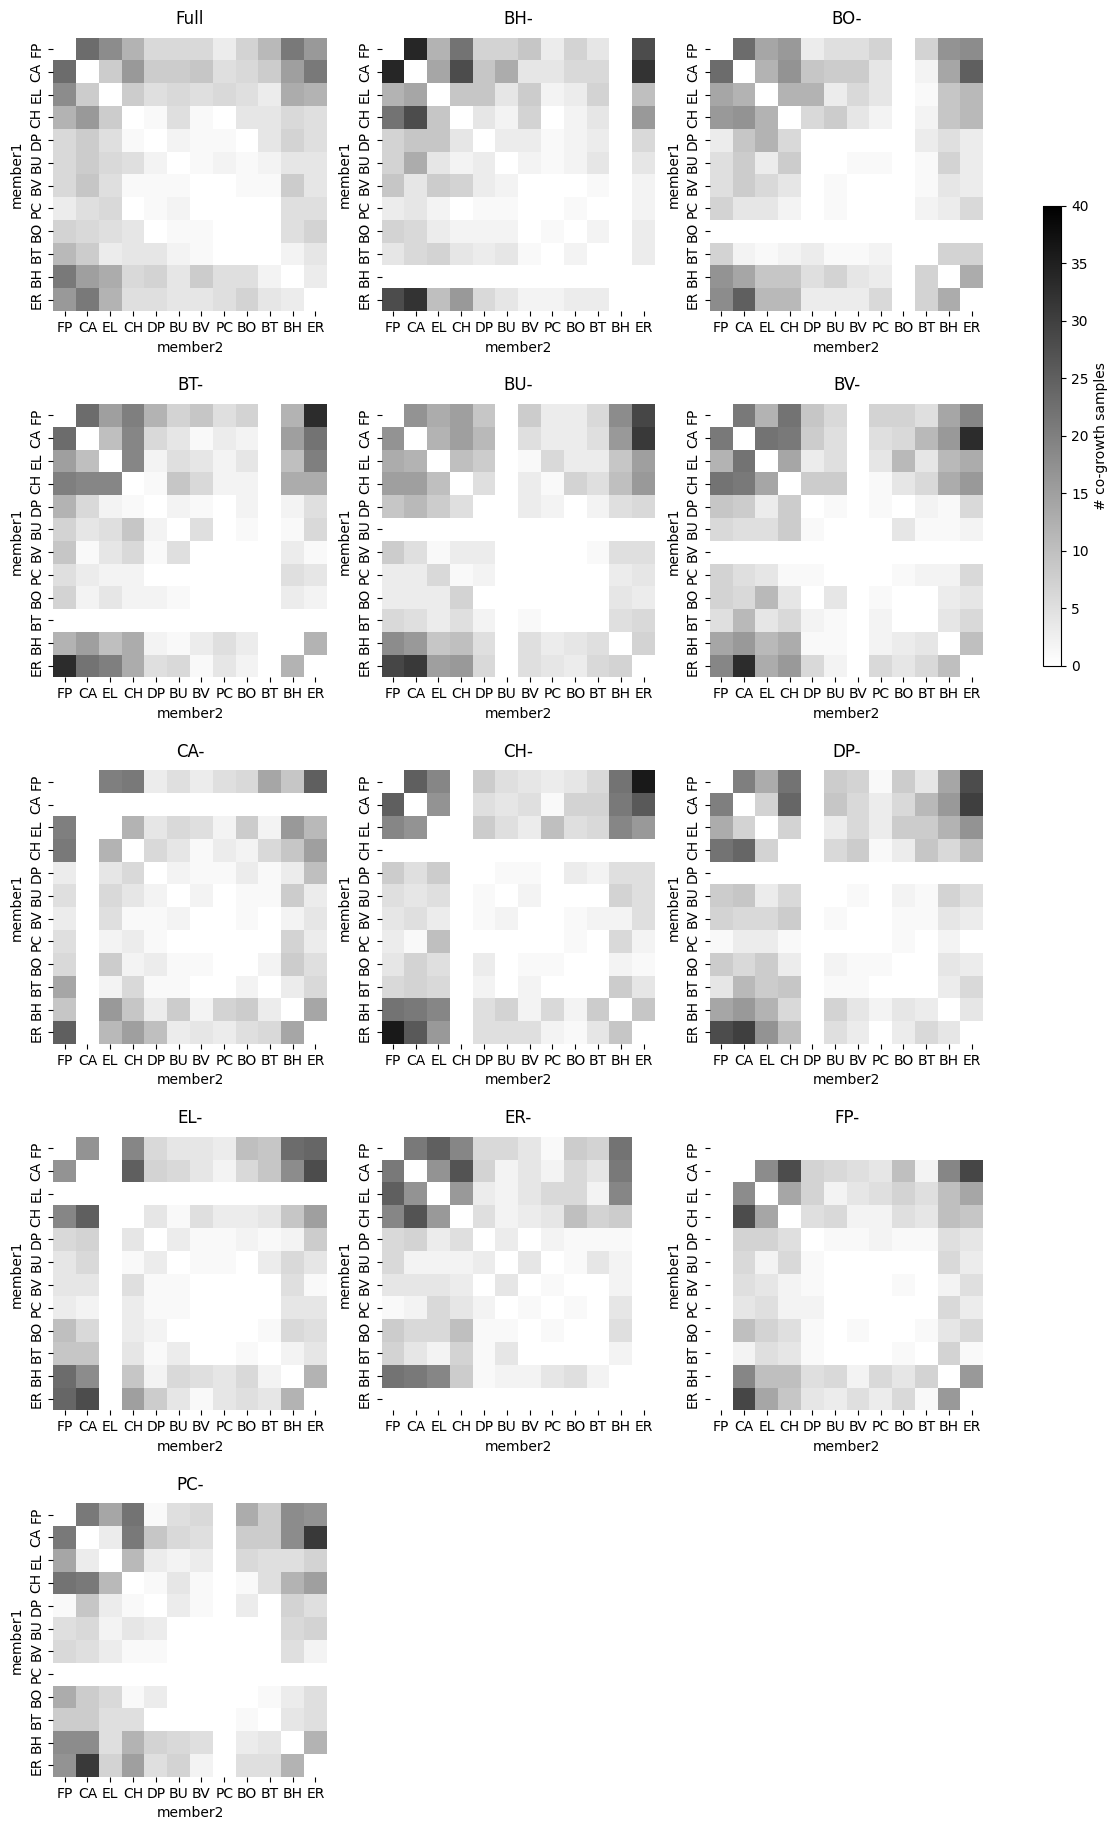

In [112]:
abundance_sim_analysis.plot_co_growth_count_venturelli(abundance_filtered,vmax=40)

### Correlating the output from different communities

In [113]:
communities = list(abundance_filtered.community.sort_values().unique())
communities.remove("NONE")

co_growth_count_none,member_abund_none = abundance_sim_analysis.make_co_growth_count_matrix(abundance_filtered,"NONE")
member_abund_dict = {}
spearman_corr = {}
member_abund_dict["None"]=member_abund_none

for i,community in enumerate(communities):

    co_growth_count_comm,member_abund = abundance_sim_analysis.make_co_growth_count_matrix(abundance_filtered,community)
    missing_member = community.replace("-","")
    
    # Remove row and column with missing member
    co_growth_count_none_copy = co_growth_count_none.copy()
    co_growth_count_none_copy = co_growth_count_none_copy.loc[co_growth_count_none_copy.index!=missing_member,co_growth_count_none_copy.index!=missing_member]
    
    co_growth_count_comm_copy = co_growth_count_comm.copy()
    co_growth_count_comm_copy = co_growth_count_comm_copy.loc[co_growth_count_comm_copy.index!=missing_member,co_growth_count_comm_copy.index!=missing_member]
    
    # Make series 
    series_none = co_growth_count_none_copy.stack()
    series_none.name ="NONE"
    series_comm = co_growth_count_comm_copy.stack()
    series_comm.name=community
    
    # Combne
    none_vs_comm = pd.concat([series_none,series_comm],axis=1)
    
    # Add spearman 
    array =none_vs_comm.values
    r, p = sp.stats.spearmanr(a=array)
    
    spearman_corr[community] = {"r":r,"p":p}
    member_abund_dict[community]=member_abund


[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.
[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.
[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.
[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.
[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.
[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.
[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.
[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.
[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.
[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.
[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.
[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.
[INFO] Make_co_g

#### Correlation with full community (interactions with missing member are excluded!)

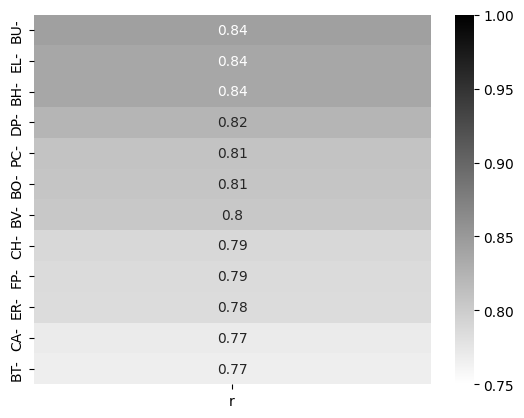

In [114]:
ax = sns.heatmap(pd.DataFrame(spearman_corr).T[["r"]].sort_values("r",ascending=False),cmap="binary",vmin=0.75,vmax=1,annot=True)

### Winners and loosers

#### Full community

<Axes: ylabel='member'>

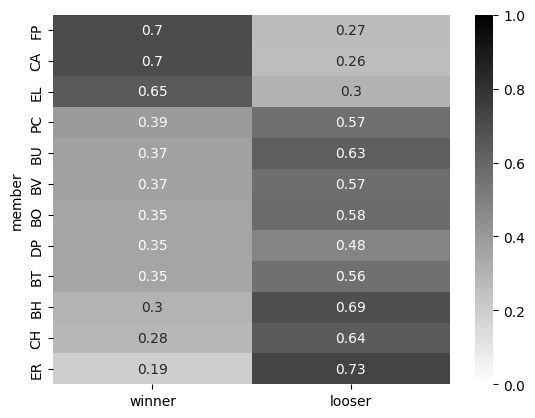

In [115]:
abundance_no_zeros = member_abund_none[member_abund_none>1e-6]
total_counts = abundance_no_zeros.count()

winner = abundance_no_zeros.eq(abundance_no_zeros.max(axis=1),axis=0).sum().sort_values()
winner = (winner/total_counts).sort_values()
winner.name="winner"

looser = abundance_no_zeros.eq(abundance_no_zeros.min(axis=1),axis=0).sum().sort_values()
looser = (looser/total_counts).sort_values()
looser.name="looser"

winner_looser = pd.concat([winner,looser],axis=1)
winner_looser = winner_looser.sort_values(by="winner",ascending=False)
sns.heatmap(winner_looser,cmap="binary",vmin=0,vmax=1,annot=True)

#### All communities

<Axes: ylabel='member'>

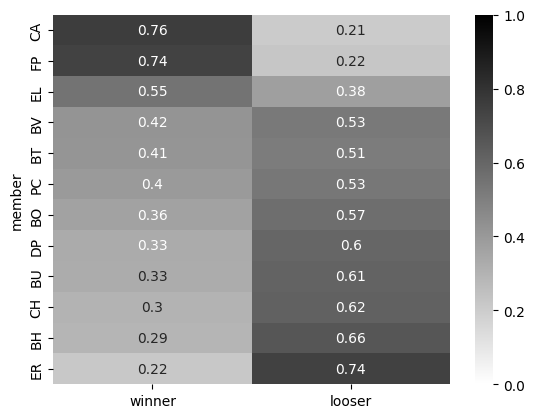

In [116]:
member_abund_all = pd.concat(member_abund_dict).fillna(0)
abundance_no_zeros = member_abund_all[member_abund_all>1e-6]
total_counts = abundance_no_zeros.count()

winner = abundance_no_zeros.eq(abundance_no_zeros.max(axis=1),axis=0).sum().sort_values()
winner = (winner/total_counts).sort_values()
winner.name="winner"

looser = abundance_no_zeros.eq(abundance_no_zeros.min(axis=1),axis=0).sum().sort_values()
looser = (looser/total_counts).sort_values()
looser.name="looser"

winner_looser = pd.concat([winner,looser],axis=1)
winner_looser = winner_looser.sort_values(by="winner",ascending=False)
sns.heatmap(winner_looser,cmap="binary",vmin=0,vmax=1,annot=True)

### Comparing relative abundance of co-growers vs non-co-growers

**Co-growers**: The members forming cluster in the clustermap of full community

**Independent growers**: The members not in cluster in clustermap.

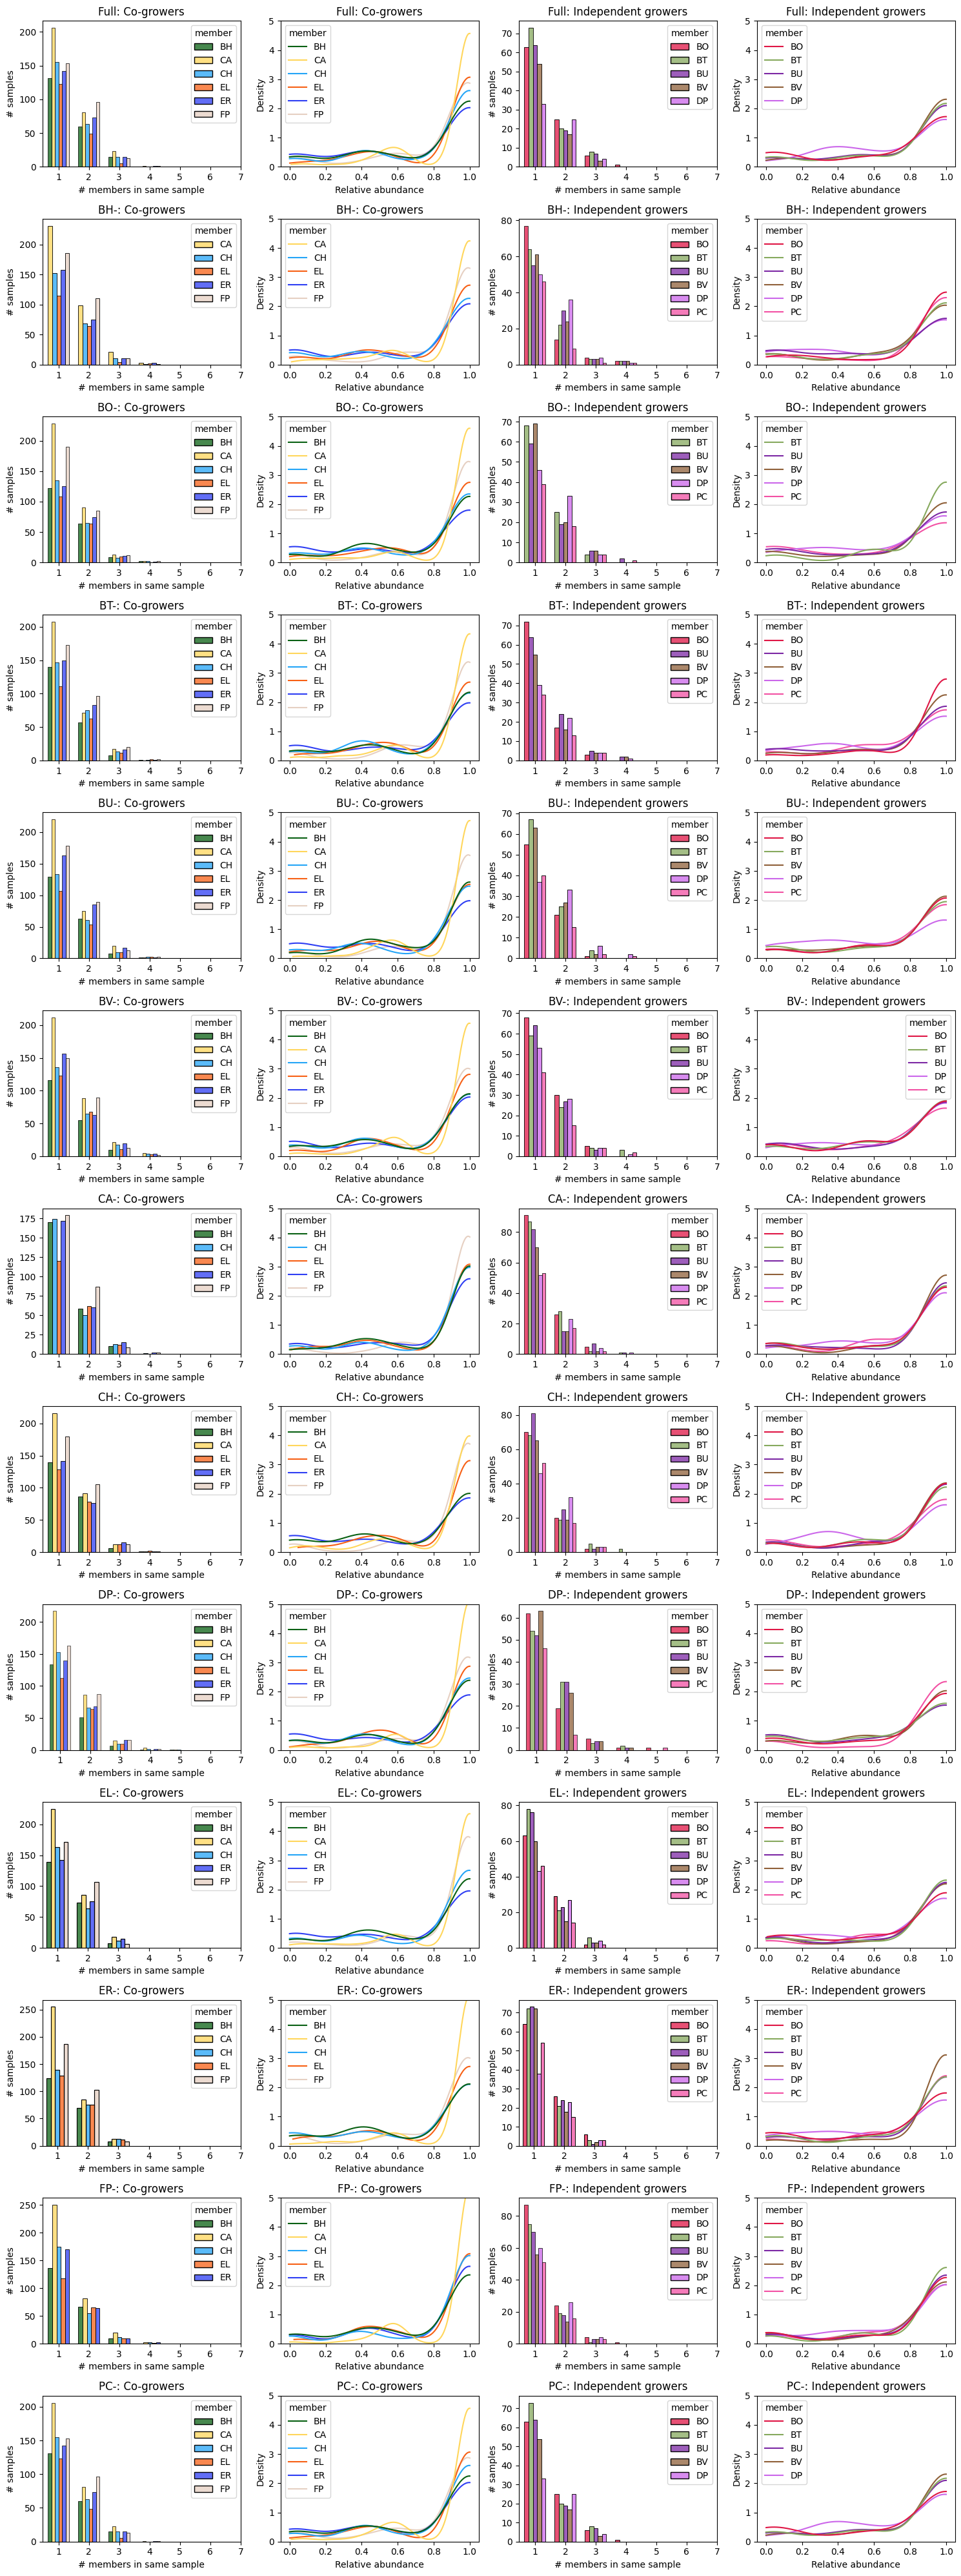

In [117]:

co_growers = set(["CH","EL","BH","ER","CA","FP"])

fig,axs =abundance_sim_analysis.plot_co_ind_growers_venturelli(abundances_df,co_growers=co_growers)

In [118]:
exp_abundance = []

for file in listdir("../data/Venturelli2018/generated/communities_steadiercom/"):
    if file.endswith(".tsv"):
        
        exp_abund = pd.read_csv("../data/Venturelli2018/generated/communities_steadiercom/"+file,sep="\t",header=None)
        name = file.split("_")[0]
        exp_abund.name=f"{name}"
        exp_abundance.append(exp_abund)

def change_name(x):
    names =x.split("_")
    name = names[0][0].upper()+names[1][0].upper()
    return name

exp_abundance_df = pd.concat(exp_abundance)
exp_abundance_df.columns = ["community","member","abundance"]
exp_abundance_df = exp_abundance_df.set_index(["community","member"])["abundance"].unstack().fillna(0)
exp_abundance_df.columns = exp_abundance_df.columns.map(change_name)
exp_abundance_df

exp_abundance_df.sort_index(axis=1,inplace=True)

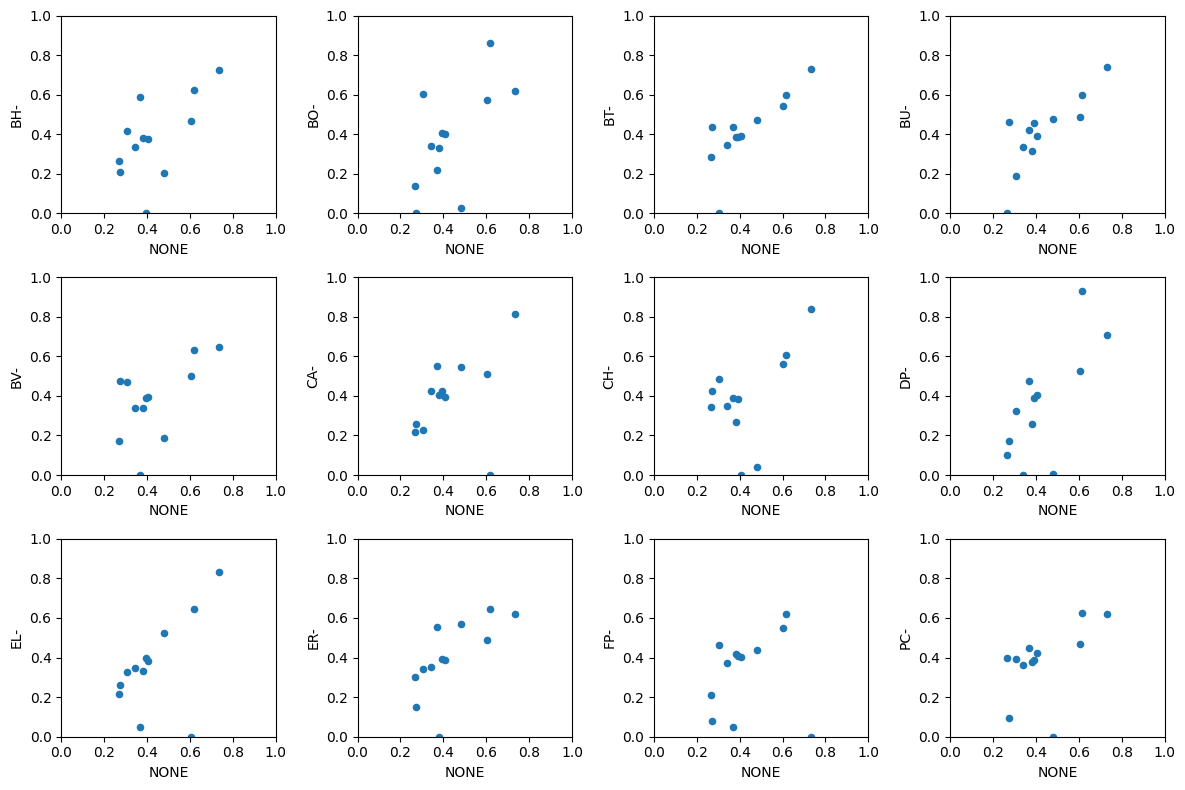

In [119]:
test = abundance_filtered[["member","relative_abundance","community"]].groupby(["member","community"]).median().unstack().fillna(0)
test = test.droplevel(0,axis=1)
none = test["NONE"]
test = test.loc[:,test.columns!="NONE"]
fig,axs = plt.subplots(3,4,figsize=(12,8))
ax_flat = axs.flatten()
for i,community in enumerate(test.columns):
    pd.concat([test[community],none],axis=1).plot(x="NONE",y=community,kind="scatter",ylim=[0,1],xlim=[0,1],ax=ax_flat[i])
    
fig.tight_layout()

In [120]:
df8 = abundances_df.groupby(['community', 'member'], as_index=False).agg({"relative_abundance": (lambda x: sum(x)/3000)})
df8 = df8.pivot_table(index='member', columns='community', values='relative_abundance', fill_value=0)
df8 = df8.T.sort_index(axis=1)

/var/folders/mc/1rm74nkd4s78l46281nyt5wm0000gn/T/ipykernel_93006/3232669054.py:22: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


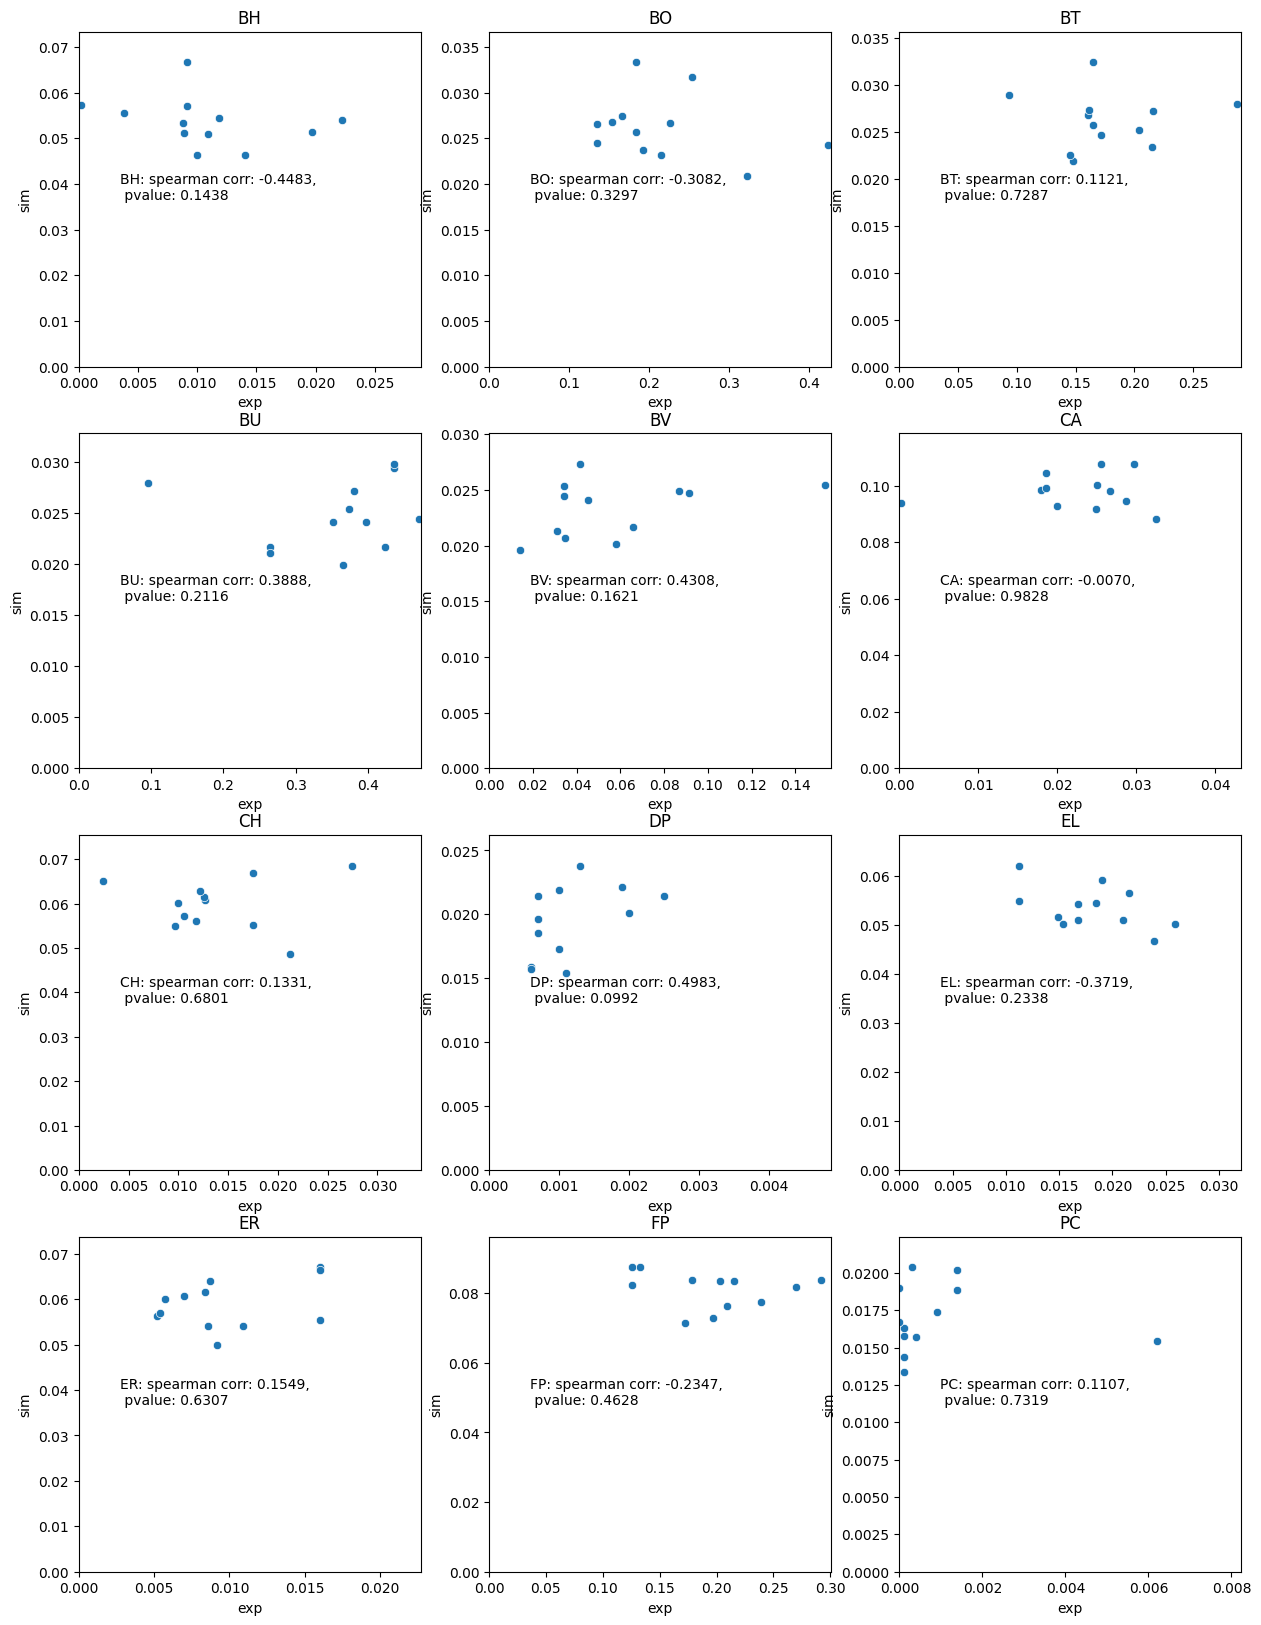

In [121]:
from scipy.stats import spearmanr

fig,axs = plt.subplots(4,3,figsize=(15,20))
axs_flat = axs.flatten()


for i,member in enumerate(exp_abundance_df.columns):
    exp = exp_abundance_df[member]
    exp = exp[exp.index!=f"{member}-"].copy()
    exp.name="exp"
    sim = df8[member]
    sim = sim[sim.index!=f"{member}-"].copy()
    sim.name="sim"

    stat = spearmanr(exp,sim)
    sns.scatterplot(x=exp,y=sim,ax=axs_flat[i])
    axs_flat[i].set_title(member)
    axs_flat[i].set_ylim([0,max(sim)+max(sim)*0.1])
    axs_flat[i].set_xlim([0,max(exp)+max(sim)*0.1])
    
    plt.text(y=0.5,x=0.12,s=f"{member}: spearman corr: {stat.statistic:.4f},\n pvalue: {stat.pvalue:.4f}",transform=axs_flat[i].transAxes)
fig.tight_layout()

/var/folders/mc/1rm74nkd4s78l46281nyt5wm0000gn/T/ipykernel_93006/4202540913.py:24: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


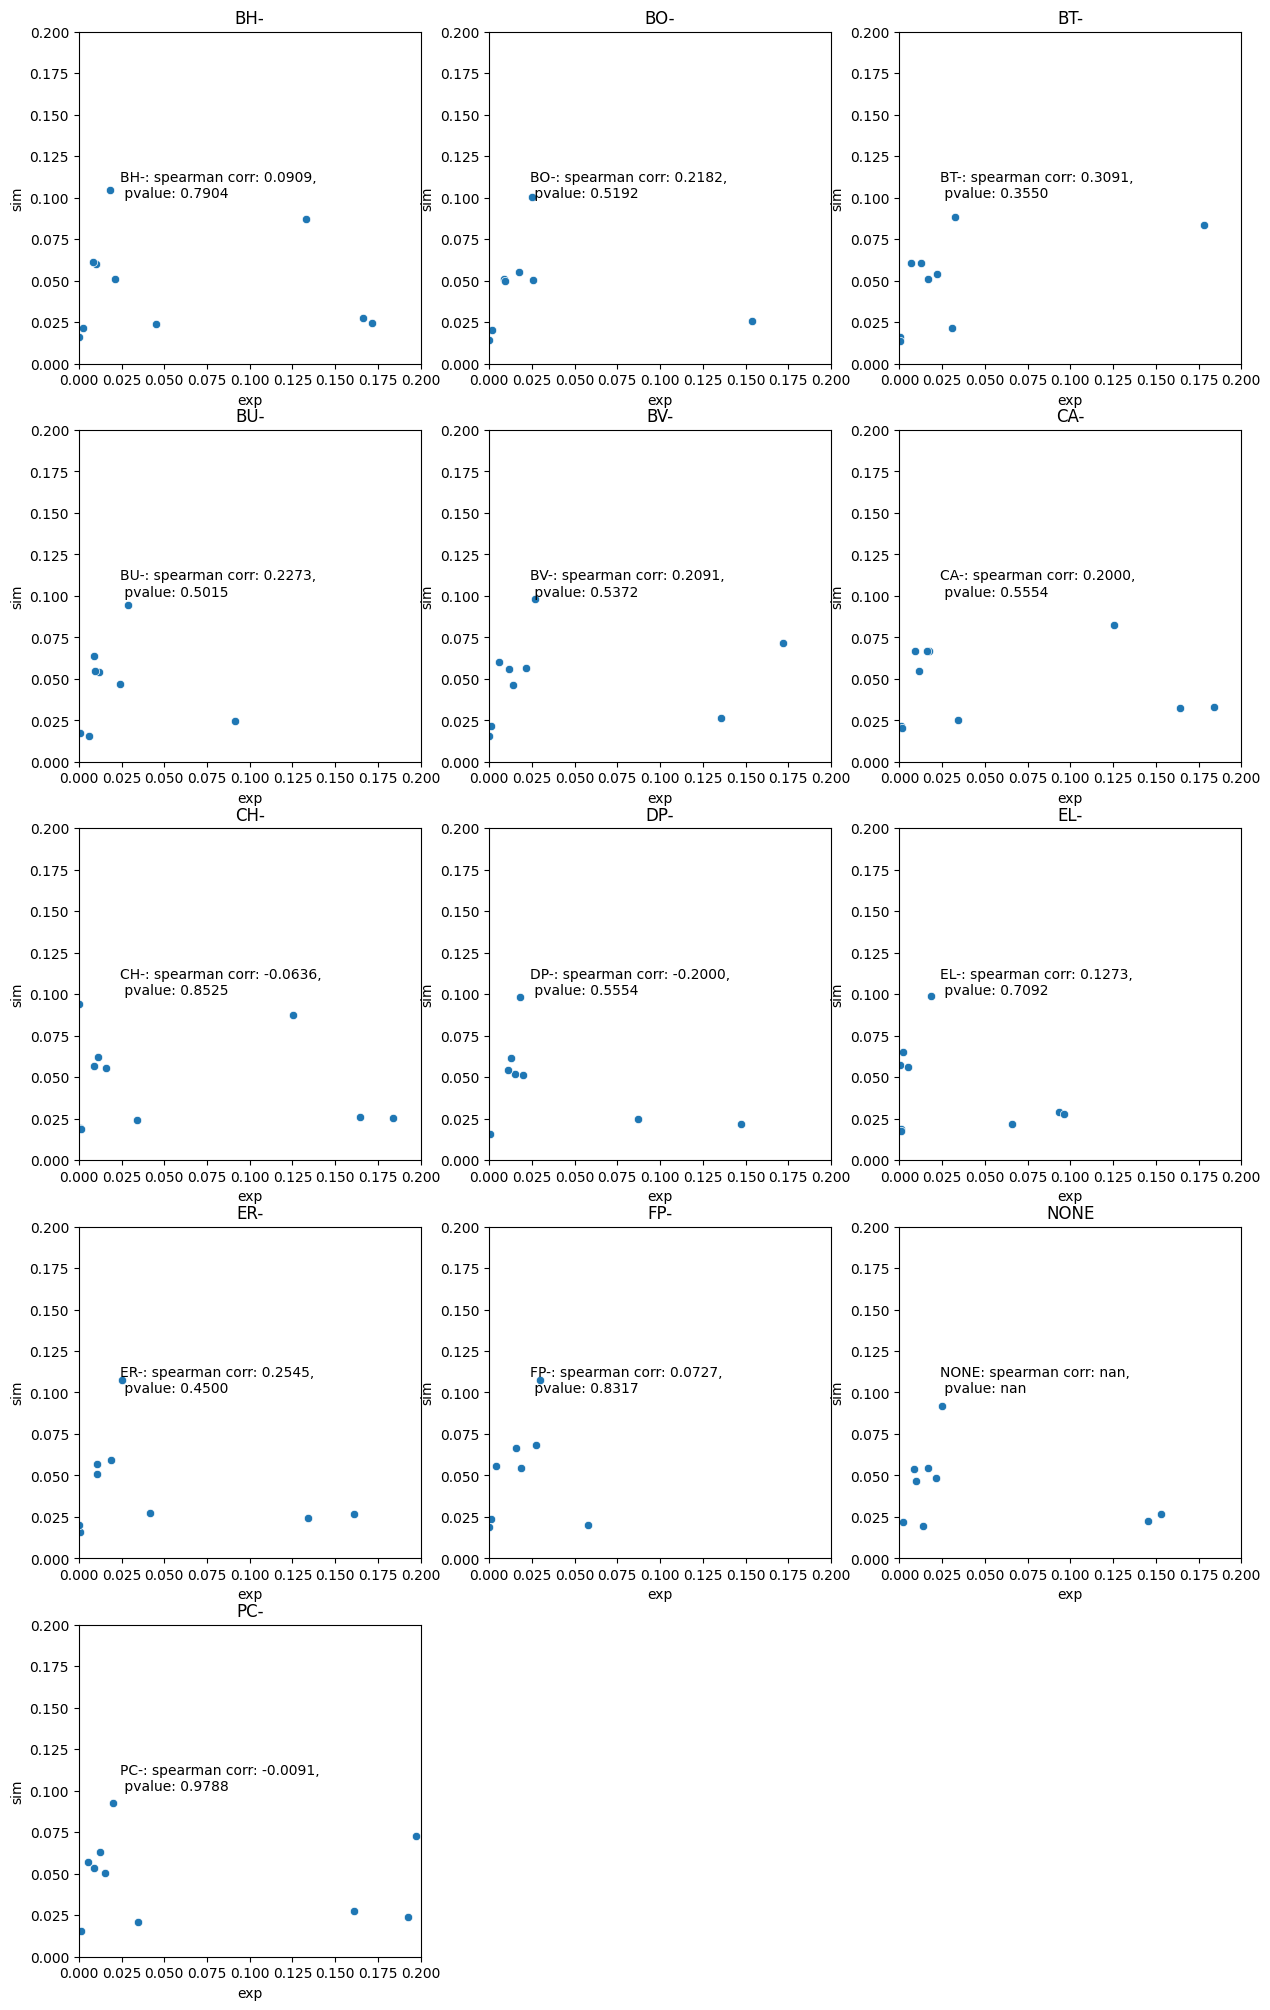

In [147]:
fig,axs = plt.subplots(5,3,figsize=(15,25))
axs_flat = axs.flatten()


for i,member in enumerate(exp_abundance_df.index):
    
    exp = exp_abundance_df.loc[member]
    exp = exp[exp.index!=member[:-1]].copy()
    exp.name="exp"
    sim = df8.loc[member]
    sim = sim[sim.index!=member[:-1]].copy()
    sim.name="sim"
    stat = spearmanr(exp,sim)
    sns.scatterplot(x=exp,y=sim,ax=axs_flat[i])
    axs_flat[i].set_title(member)
    
    
    axs_flat[i].set_ylim([0,0.2])
    axs_flat[i].set_xlim([0,0.2])
    plt.text(y=0.5,x=0.12,s=f"{member}: spearman corr: {stat.statistic:.4f},\n pvalue: {stat.pvalue:.4f}",transform=axs_flat[i].transAxes)
    
axs_flat[-1].set_axis_off()
axs_flat[-2].set_axis_off()
fig.tight_layout()
#plt.savefig("community_abundance_steadiercom.png")

Text(0.5, 1.0, 'SteadierCom')

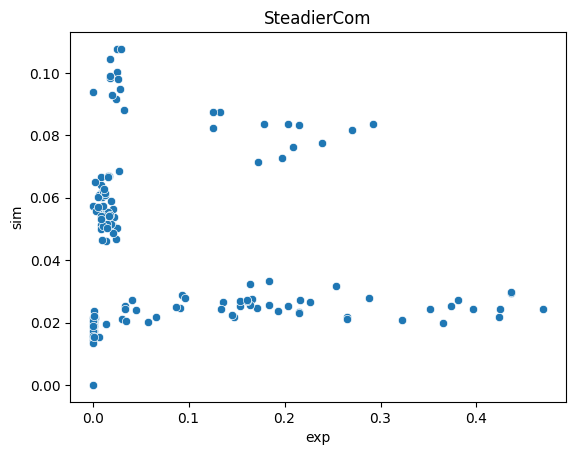

In [148]:
np.fill_diagonal(exp_abundance_df.values, np.nan)
np.fill_diagonal(df8.values, np.nan)
exp = exp_abundance_df.stack().sort_index()
exp.name="exp"
sim = df8.stack().sort_index()
sim.name="sim"

sns.scatterplot(x=exp,y=sim)
plt.title("SteadierCom")
#plt.savefig("community_abundance_all_steadiercom.png")

In [149]:
joined = pd.concat([exp,sim],axis=1)

stat = spearmanr(joined.exp,joined.sim)
stat

SignificanceResult(statistic=np.float64(0.13216872672392763), pvalue=np.float64(0.11430448941315696))

In [150]:
joined[joined.exp<0.05].index.get_level_values(1).value_counts()

member
CA    12
CH    12
DP    12
EL    12
ER    12
PC    12
BH    12
BV     7
Name: count, dtype: int64

<Axes: xlabel='exp', ylabel='sim'>

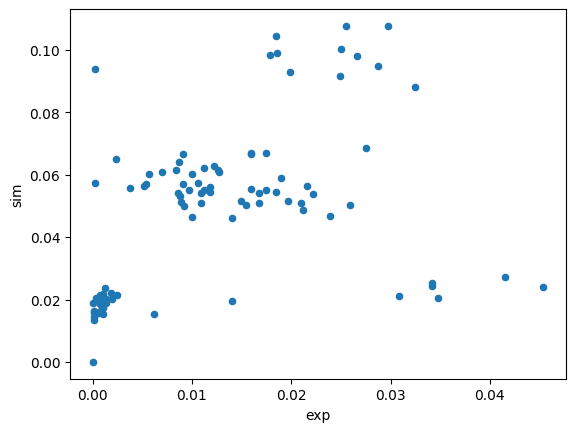

In [151]:
joined[(joined.exp<0.05)].plot(x="exp",y="sim",kind="scatter")

In [152]:
stat = spearmanr(joined[(joined.exp<0.05)].exp,joined[(joined.exp<0.05)].sim)
stat

SignificanceResult(statistic=np.float64(0.5032035627035678), pvalue=np.float64(3.7017830599109535e-07))

In [153]:
set(joined[(joined.exp<0.05)].index.get_level_values(1))

{'BH', 'BV', 'CA', 'CH', 'DP', 'EL', 'ER', 'PC'}

In [154]:
joined[joined.sim<0.03].index.get_level_values(1).value_counts()

member
BU    12
BV    12
DP    12
PC    12
BT    11
BO    10
Name: count, dtype: int64

<Axes: xlabel='exp', ylabel='sim'>

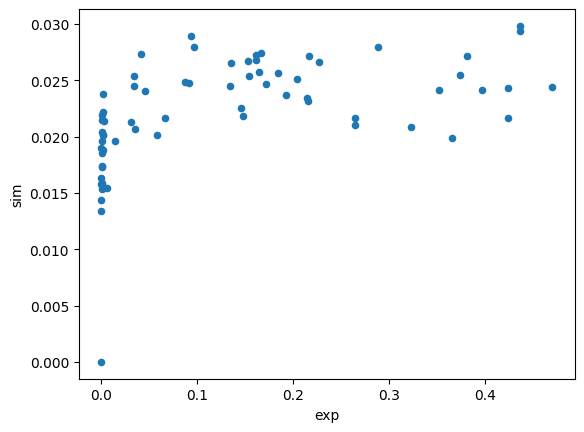

In [155]:
joined[(joined.sim<0.03)].plot(x="exp",y="sim",kind="scatter")

In [156]:
stat = spearmanr(joined[(joined.sim<0.03)].exp,joined[(joined.sim<0.03)].sim)
stat

SignificanceResult(statistic=np.float64(0.6823131851515581), pvalue=np.float64(1.0744725092937408e-10))